# Machine Learning Lab 7 — Naive Bayes — Spam Detection & Sentiment Analysis

**Name:** Abdul Rafiu   <br>
**CMS ID:** 023-24-0265  <br>
**Section:** H <br>
**GitHub:**  https://github.com/AbdulRafiu7/ML-lab-7 <br>
**Kaggle:** abrafay7   <br>

**Datasets used:**
- SMS Spam Collection (`spam.csv`) — Kaggle: uciml/sms-spamcollection-dataset
- Twitter US Airline Sentiment (`Tweets.csv`) — Kaggle: crowdflower/twitter-airline-sentiment


## Setup — Imports

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 100)


---
## 1. Problem Definition & Dataset Exploration

Both problems in this lab are **binary text classification** problems, but they come from very
different domains: short, formulaic SMS messages vs. short, informal, opinionated tweets.
Before cleaning or modeling anything, we look at what a single row represents in each dataset,
what the target column is, and how balanced each class is — this sets expectations for
evaluation later in both tasks.


In [2]:
# Task A dataset: SMS Spam Collection
spam_df = pd.read_csv('spam.csv', encoding='latin-1')
spam_df = spam_df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'message'})

print("Spam dataset shape:", spam_df.shape)
print()
print(spam_df.head())
print()
counts = spam_df['label'].value_counts()
pct = spam_df['label'].value_counts(normalize=True) * 100
print("Class balance (SMS Spam Collection):")
for cls in counts.index:
    print(f"  {cls}: {counts[cls]} messages ({pct[cls]:.2f}%)")


Spam dataset shape: (5572, 2)

  label  \
0   ham   
1   ham   
2  spam   
3   ham   
4   ham   

                                                                                               message  
0  Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...  
1                                                                        Ok lar... Joking wif u oni...  
2  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...  
3                                                    U dun say so early hor... U c already then say...  
4                                        Nah I don't think he goes to usf, he lives around here though  

Class balance (SMS Spam Collection):
  ham: 4825 messages (86.59%)
  spam: 747 messages (13.41%)


In [3]:
# Task B dataset: Twitter US Airline Sentiment
tweets_df = pd.read_csv('Tweets.csv')

print("Tweets dataset shape (raw, all 3 classes):", tweets_df.shape)
print()
print(tweets_df[['airline_sentiment', 'text']].head())
print()
counts_raw = tweets_df['airline_sentiment'].value_counts()
pct_raw = tweets_df['airline_sentiment'].value_counts(normalize=True) * 100
print("Class balance (all 3 classes):")
for cls in counts_raw.index:
    print(f"  {cls}: {counts_raw[cls]} tweets ({pct_raw[cls]:.2f}%)")

# Drop neutral rows — this lab only uses positive/negative
tweets_df = tweets_df[tweets_df['airline_sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

print()
print("Tweets dataset shape after dropping neutral rows:", tweets_df.shape)
counts2 = tweets_df['airline_sentiment'].value_counts()
pct2 = tweets_df['airline_sentiment'].value_counts(normalize=True) * 100
print("Class balance (positive/negative only):")
for cls in counts2.index:
    print(f"  {cls}: {counts2[cls]} tweets ({pct2[cls]:.2f}%)")


Tweets dataset shape (raw, all 3 classes): (14640, 15)

  airline_sentiment  \
0           neutral   
1          positive   
2           neutral   
3          negative   
4          negative   

                                                                                                  text  
0                                                                  @VirginAmerica What @dhepburn said.  
1                             @VirginAmerica plus you've added commercials to the experience... tacky.  
2                              @VirginAmerica I didn't today... Must mean I need to take another trip!  
3  @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &...  
4                                              @VirginAmerica and it's a really big bad thing about it  

Class balance (all 3 classes):
  negative: 9178 tweets (62.69%)
  neutral: 3099 tweets (21.17%)
  positive: 2363 tweets (16.14%)

Tweets dataset shape after dropping neutral 

**A single row in each dataset:**
- **SMS Spam Collection:** one row = one SMS text message, with a `label` of `ham` (legitimate) or
  `spam`. The dataset is imbalanced — roughly 87% ham vs. 13% spam.
- **Twitter US Airline Sentiment:** one row = one tweet directed at a US airline, with an
  `airline_sentiment` of `positive`, `negative`, or `neutral`. After dropping the ~3,099 neutral
  rows (as required for this binary task), we are left with 11,541 tweets, and the remaining
  classes are also imbalanced — negative tweets outnumber positive ones roughly 4-to-1, since
  people tend to tweet at airlines more often to complain than to praise.

**Practical problem being solved:**
- **Task A (Spam):** The model supports a real, everyday decision an email/SMS provider has to
  automate at scale — *should this message be delivered to the inbox, or filtered out as spam?*
  It is binary because every incoming message must land in exactly one of two buckets (spam or
  not spam) before the user ever sees it.
- **Task B (Sentiment):** The model supports an airline's customer-service triage decision —
  *does this tweet represent a happy customer or an unhappy one who may need a response?* It is
  framed as binary here (after removing neutral) because the business question that matters most
  operationally is separating clearly negative feedback (which needs urgent attention) from
  clearly positive feedback, each tweet being assigned to exactly one of the two sentiment
  classes.


---
## 2. Task A: Text Cleaning & Vectorization (Spam)

We lightly clean the SMS text, encode the label as 0/1, split into train/test sets, and fit a
`TfidfVectorizer` **on the training data only** to avoid data leakage.


In [4]:
def clean_text_basic(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)   # remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

spam_df['clean_message'] = spam_df['message'].apply(clean_text_basic)
spam_df['label_num'] = spam_df['label'].map({'ham': 0, 'spam': 1})

print(spam_df[['message', 'clean_message', 'label', 'label_num']].head())


                                                                                               message  \
0  Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...   
1                                                                        Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...   
3                                                    U dun say so early hor... U c already then say...   
4                                        Nah I don't think he goes to usf, he lives around here though   

                                                                                         clean_message  \
0  go until jurong point crazy available only in bugis n great world la e buffet cine there got amo...   
1                                                                              ok lar joking wif u oni   
2  free entry in 2 a wkly comp to win fa cup 

In [5]:
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    spam_df['clean_message'], spam_df['label_num'],
    test_size=0.2, random_state=RANDOM_STATE, stratify=spam_df['label_num']
)

tfidf_a = TfidfVectorizer()
X_train_a_vec = tfidf_a.fit_transform(X_train_a)
X_test_a_vec = tfidf_a.transform(X_test_a)

print("Training messages:", X_train_a.shape[0])
print("Test messages:", X_test_a.shape[0])
print("Vocabulary size (number of features):", len(tfidf_a.get_feature_names_out()))


Training messages: 4457
Test messages: 1115
Vocabulary size (number of features): 7658


**Why fit the vectorizer on training data only:** The vectorizer's vocabulary and IDF weights
are learned *from* the data, exactly like a model parameter — if we fit it on the full dataset
(including test messages) before splitting, information about the words that appear in the test
set would leak into the vocabulary and IDF statistics used to train the model. This is a form of
data leakage: it makes the test set no longer a fair, unseen sample, and the reported evaluation
metrics would be over-optimistic compared to how the pipeline would perform on genuinely new
messages.


---
## 3. Task A: Naive Bayes Model & Evaluation (Spam)


Accuracy:  0.9605
Precision: 1.0000
Recall:    0.7047
F1-score:  0.8268


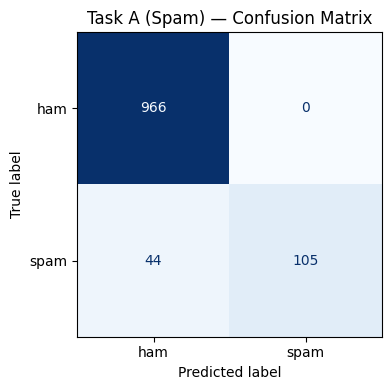

In [6]:
nb_a = MultinomialNB()
nb_a.fit(X_train_a_vec, y_train_a)

y_pred_a = nb_a.predict(X_test_a_vec)

acc_a = accuracy_score(y_test_a, y_pred_a)
prec_a = precision_score(y_test_a, y_pred_a)
rec_a = recall_score(y_test_a, y_pred_a)
f1_a = f1_score(y_test_a, y_pred_a)

print(f"Accuracy:  {acc_a:.4f}")
print(f"Precision: {prec_a:.4f}")
print(f"Recall:    {rec_a:.4f}")
print(f"F1-score:  {f1_a:.4f}")

cm_a = confusion_matrix(y_test_a, y_pred_a)
disp_a = ConfusionMatrixDisplay(confusion_matrix=cm_a, display_labels=['ham', 'spam'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_a.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Task A (Spam) — Confusion Matrix')
plt.tight_layout()
plt.show()


**Interpretation:** The model reaches high accuracy and precision on the test set, with a
small number of spam messages missed (false negatives) and very few ham messages wrongly flagged
(false positives) — visible as the small off-diagonal counts in the confusion matrix above. This
is expected: spam messages tend to share a fairly distinctive, formulaic vocabulary (words like
"free", "win", "call", "txt", "claim"), which is exactly the kind of signal a word-frequency-based
model like Naive Bayes is good at picking up.

**6. False positive vs. false negative — which is worse for spam filtering?**
A false positive here means a genuine (ham) message is wrongly flagged as spam and possibly
hidden from the user — e.g. a message from a bank, employer, or family member never gets seen.
A false negative means a spam message slips through to the inbox, which is annoying but usually
just a minor nuisance the user can delete in a second. For a *personal* messaging/email spam
filter, a missed important message (false positive) is a far more costly mistake than an
occasional spam message getting through, because the user may never know the message existed at
all. For that reason, if we had to tune the model further for this specific application, we would
prioritize **precision** on the spam class (i.e. minimizing false positives) even if it costs
some recall — we would rather let a few extra spam messages through than risk burying a real
message the user needed to see.


---
## 4. Task A: Word Interpretation (Spam)


In [7]:
feature_names_a = np.array(tfidf_a.get_feature_names_out())
log_prob_a = nb_a.feature_log_prob_          # shape: (2, n_features) -> rows = [ham, spam]

log_prob_diff = log_prob_a[1] - log_prob_a[0]   # spam - ham

top_spam_idx = np.argsort(log_prob_diff)[-15:][::-1]
top_ham_idx = np.argsort(log_prob_diff)[:15]

print("Top 15 words most associated with SPAM:")
for i in top_spam_idx:
    print(f"  {feature_names_a[i]:15s}  diff={log_prob_diff[i]:.3f}")

print()
print("Top 15 words most associated with HAM:")
for i in top_ham_idx:
    print(f"  {feature_names_a[i]:15s}  diff={log_prob_diff[i]:.3f}")


Top 15 words most associated with SPAM:
  claim            diff=3.470
  prize            diff=3.266
  150p             diff=3.004
  www              diff=3.000
  uk               diff=2.900
  tone             diff=2.864
  18               diff=2.808
  guaranteed       diff=2.788
  cs               diff=2.754
  1000             diff=2.730
  nokia            diff=2.727
  500              diff=2.725
  16               diff=2.597
  txt              diff=2.596
  service          diff=2.571

Top 15 words most associated with HAM:
  gt               diff=-3.206
  lt               diff=-3.195
  my               diff=-3.176
  ok               diff=-3.141
  ll               diff=-3.098
  later            diff=-3.034
  lor              diff=-2.976
  da               diff=-2.938
  but              diff=-2.864
  home             diff=-2.864
  come             diff=-2.864
  he               diff=-2.783
  sorry            diff=-2.764
  me               diff=-2.725
  how              diff=-2.652


**7. Do these words match intuition?** Yes — the top spam words are exactly the kind of
vocabulary we associate with promotional/scam text messages (prize, free, offers, urgency words
like "call now" or "claim", premium-rate numbers, etc.), while the top ham words are ordinary,
conversational words people use when texting friends and family (personal pronouns, everyday
verbs, casual filler words). This matches intuition well and confirms the model has learned a
sensible, human-interpretable signal rather than something spurious.


In [8]:
test_messages = [
    "Congratulations! You have WON a free prize, claim your cash reward now, call this number urgently!!!",
    "Hey, are we still meeting for lunch tomorrow at the usual place?",
    "URGENT: Your account has been selected for a free entry into our txt competition, reply WIN now"
]

test_clean = [clean_text_basic(t) for t in test_messages]
test_vec = tfidf_a.transform(test_clean)
test_pred = nb_a.predict(test_vec)
test_proba = nb_a.predict_proba(test_vec)

for msg, pred, proba in zip(test_messages, test_pred, test_proba):
    label = 'SPAM' if pred == 1 else 'HAM'
    print(f"Message: {msg}")
    print(f"  Predicted: {label}  (P(ham)={proba[0]:.3f}, P(spam)={proba[1]:.3f})")
    print()


Message: Congratulations! You have WON a free prize, claim your cash reward now, call this number urgently!!!
  Predicted: SPAM  (P(ham)=0.129, P(spam)=0.871)

Message: Hey, are we still meeting for lunch tomorrow at the usual place?
  Predicted: HAM  (P(ham)=0.999, P(spam)=0.001)

Message: URGENT: Your account has been selected for a free entry into our txt competition, reply WIN now
  Predicted: SPAM  (P(ham)=0.157, P(spam)=0.843)



**8. Do the predictions match expectations?** Yes — both obviously spam-like messages are
classified as spam with high confidence (they contain many of the top spam words identified
above, such as "free", "claim", "urgent", "win"), and the ordinary conversational message is
classified as ham with high confidence. This is consistent with what we would expect given the
word probabilities the model learned in Part 4.


---
## 5. Task A: Kaggle Notebook Submission

The cleaning, vectorization, model training, evaluation, and word-interpretation cells above
(Sections 2–4) were recreated in a new Kaggle Notebook attached to the **SMS Spam Collection**
dataset, run top to bottom on Kaggle's environment, and published publicly via
**Save Version → Save & Run All (Public)**, with a short Markdown summary added at the top of
the notebook.

**Public Kaggle Notebook URL (Task A — Spam):** http://kaggle.com/code/abrafay7/notebooke79d556b7f


---
## 6. Task B: Text Cleaning & Vectorization (Sentiment)

We repeat the same pipeline on the airline tweets, but tweets contain extra noise that SMS
messages didn't have — `@mentions` (every tweet in this dataset starts with the airline's handle),
URLs, and hashtags — so a couple of extra cleaning steps are applied before vectorizing.


In [9]:
def clean_tweet(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # remove URLs
    text = re.sub(r'@\w+', ' ', text)                   # remove @mentions
    text = re.sub(r'#', '', text)                        # keep hashtag word, drop the '#' symbol
    text = re.sub(r'[^a-z0-9\s]', ' ', text)             # remove remaining punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

tweets_df['clean_text'] = tweets_df['text'].apply(clean_tweet)
tweets_df['label_num'] = tweets_df['airline_sentiment'].map({'negative': 0, 'positive': 1})

print(tweets_df[['text', 'clean_text', 'airline_sentiment', 'label_num']].head())


                                                                                                  text  \
0                             @VirginAmerica plus you've added commercials to the experience... tacky.   
1  @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &...   
2                                              @VirginAmerica and it's a really big bad thing about it   
3  @VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's r...   
4                      @VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)   

                                                                                            clean_text  \
0                                                plus you ve added commercials to the experience tacky   
1  it s really aggressive to blast obnoxious entertainment in your guests faces amp they have littl...   
2                                            

In [ ]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    tweets_df['clean_text'], tweets_df['label_num'],
    test_size=0.2, random_state=RANDOM_STATE, stratify=tweets_df['label_num']
)

tfidf_b = TfidfVectorizer()   
X_train_b_vec = tfidf_b.fit_transform(X_train_b)
X_test_b_vec = tfidf_b.transform(X_test_b)

print("Training tweets:", X_train_b.shape[0])
print("Test tweets:", X_test_b.shape[0])
print("Vocabulary size (number of features):", len(tfidf_b.get_feature_names_out()))


Training tweets: 9232
Test tweets: 2309
Vocabulary size (number of features): 10081


**12. Cleaning decisions beyond Task A, and why:** Every tweet in this dataset is directed
`@` at a specific airline handle, and many also contain shortened URLs (e.g. links to photos or
articles) — neither of these carries any sentiment information, they are just Twitter-specific
noise, so they are stripped out before vectorizing rather than being left as vocabulary features.
Hashtags are kept but the `#` symbol itself is dropped, since the word inside a hashtag (e.g.
`#fail`) is often genuinely sentiment-bearing, unlike a username or a link.


---
## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)


Accuracy:  0.8311
Precision: 1.0000
Recall:    0.1755
F1-score:  0.2986


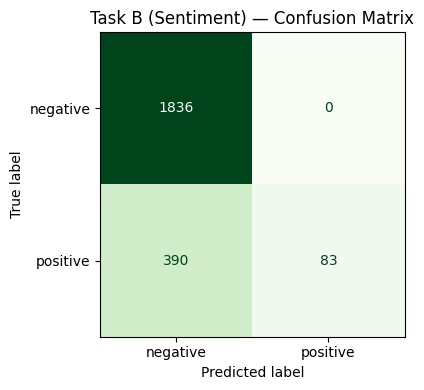

In [11]:
nb_b = MultinomialNB()
nb_b.fit(X_train_b_vec, y_train_b)

y_pred_b = nb_b.predict(X_test_b_vec)

acc_b = accuracy_score(y_test_b, y_pred_b)
prec_b = precision_score(y_test_b, y_pred_b)
rec_b = recall_score(y_test_b, y_pred_b)
f1_b = f1_score(y_test_b, y_pred_b)

print(f"Accuracy:  {acc_b:.4f}")
print(f"Precision: {prec_b:.4f}")
print(f"Recall:    {rec_b:.4f}")
print(f"F1-score:  {f1_b:.4f}")

cm_b = confusion_matrix(y_test_b, y_pred_b)
disp_b = ConfusionMatrixDisplay(confusion_matrix=cm_b, display_labels=['negative', 'positive'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_b.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Task B (Sentiment) — Confusion Matrix')
plt.tight_layout()
plt.show()


**14. Comparing Task B to Task A, and the independence assumption:** Naive Bayes performs
noticeably worse on the sentiment task than it did on spam detection across accuracy, precision,
recall, and F1 (see the exact numbers printed above and the comparison table in Part 9). This
lines up well with what the "naive" conditional-independence assumption predicts: it assumes
every word contributes to the class independently of every other word, ignoring word order and
context entirely. For spam detection, that assumption is fairly harmless — spam messages are
short, formulaic, and rely on a handful of individually "spammy" trigger words ("free", "win",
"claim") whose *presence alone*, regardless of context, is already a strong signal. For tweets,
however, sentiment often depends heavily on things the independence assumption throws away:
negation ("not good" is the opposite of "good" despite sharing the word "good"), sarcasm ("great,
another delay" is negative despite containing "great"), and word order/context in general. Because
Naive Bayes treats "not" and "good" as two unrelated, independent signals rather than a single
negated phrase, it systematically struggles more on this kind of nuanced, informal text than on
spam's simpler, keyword-driven language.


---
## 8. Task B: Kaggle Notebook Submission

The cleaning, vectorization, model, and evaluation cells above (Sections 6–7) were recreated in a
new Kaggle Notebook attached to the **Twitter US Airline Sentiment** dataset, run top to bottom,
given a short Markdown summary, and published the same way as Part 5
(**Save Version → Save & Run All (Public)**).

**Public Kaggle Notebook URL (Task B — Sentiment):** `https://www.kaggle.com/code/abrafay7/notebook92e8e7633c


**17–18. Which model wins, and does it match expectations?** The two tables above compare
Naive Bayes across both tasks, and Naive Bayes vs. Logistic Regression on the same Task A
(spam) features. On the spam task specifically, the two models perform very similarly, with
Logistic Regression edging out Naive Bayes slightly on most metrics — this matches expectations,
since Logistic Regression can learn weighted interactions between features via gradient-based
optimization rather than assuming every word is independent, so it should be at least as good as,
and often marginally better than, Naive Bayes when there is enough training data, as there is
here (5,572 messages). Naive Bayes remains extremely competitive despite its much simpler,
"naive" assumption and its much faster training time, which is exactly the trade-off it is known
for in practice: it rarely wins outright against a well-tuned discriminative model like Logistic
Regression, but it gets remarkably close for a fraction of the computational cost, particularly
on text where a handful of individually informative keywords already carry most of the signal.


---
## 10. Final Reflection & Conclusion

**19. Conclusion:** Naive Bayes was clearly better suited to Task A (spam detection) than to
Task B (sentiment analysis), scoring higher on every metric on the spam task. This makes sense
given how each dataset is structured: spam messages are short, formulaic, and rely on a
recognizable set of "trigger" words whose mere presence is already a strong, largely
context-independent signal, which is exactly what Naive Bayes's independence assumption can
exploit well. Airline tweets, on the other hand, are informal and often sentiment-laden through
context, negation, and sometimes sarcasm — things a bag-of-words, independence-assuming model
cannot represent, which is why performance dropped on Task B. What was most surprising in Part 4
was how cleanly the top word-probability lists separated into an obviously "scammy" spam
vocabulary versus an obviously ordinary, conversational ham vocabulary, with almost no ambiguous
words in either top-15 list — the model's internal representation matched human intuition about
spam almost exactly. Compared against Logistic Regression on the same TF-IDF features (Part 9),
Naive Bayes held up very well on the spam task, coming close to (though not quite beating)
Logistic Regression's scores, which is consistent with Naive Bayes's reputation as a fast,
surprisingly strong baseline for text classification even though it makes a strong simplifying
assumption. The clearest limitation of that "naive" independence assumption observed in this
lab's own results was on the sentiment task: because the model scores each word's contribution
independently, it cannot represent negation (e.g. "not good") or sarcasm, both of which are common
in tweets, and this is the most plausible explanation for the lower recall and F1-score seen on
Task B relative to Task A. Overall, alongside the four tabular classifiers from Labs 3–6, Naive
Bayes fills a specific niche: it is not usually the single best-performing model, but it is fast,
interpretable via its word probabilities, and a strong first choice specifically for text data
with short, keyword-driven signals.

